<a href="https://colab.research.google.com/github/ahmed-khaled04/bird_image_to_caption/blob/All-Models-notebook/all_models.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# All classification models — Google Colab

Run these cells from top to bottom after selecting **Runtime → Change runtime type → GPU**. This notebook uses this project's `configs/transfer.yaml`, `src.experiment`, `src.transfer`, and `src.evaluation.report`. It trains the scratch CNN and the frozen and fine-tuned ResNet-18, ResNet-50, and EfficientNet-B0 models, then compares their saved best-epoch checkpoints on the validation split.

The notebook must be in the GitHub repo before opening it from GitHub in Colab. The cleaned dataset is rebuilt from the project's Hugging Face sources when a fresh Colab session starts. Checkpoints, run JSON files, tables, and figures are stored in Google Drive so completed runs survive a Colab disconnect. The seven full runs can take hours; rerun the training cell after a disconnect to skip completed runs. A small `LIMIT` is available for a pipeline check, but its scores are **not** reportable results.

The final test split is used only in the optional last cell, after you select one model using validation results.

In [14]:
# 1. Clone the project into Colab. An existing checkout is left untouched.
import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/ahmed-khaled04/bird_image_to_caption.git"
ROOT = Path("/content/bird_image_to_caption")
if not ROOT.exists():
    subprocess.run(["git", "clone", REPO_URL, str(ROOT)], check=True)
assert (ROOT / "src").is_dir() and (ROOT / "configs/transfer.yaml").is_file(), ROOT
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
print("Project:", ROOT)
subprocess.run(["git", "rev-parse", "--short", "HEAD"], check=True)

Project: /content/bird_image_to_caption


CompletedProcess(args=['git', 'rev-parse', '--short', 'HEAD'], returncode=0)

In [15]:
# 2. Install the project's dependencies. Colab already supplies torch and torchvision.
requirements = [line.strip() for line in (ROOT / "requirements.txt").read_text().splitlines()
                if line.strip() and not line.lstrip().startswith("#")
                and line.strip() not in {"torch", "torchvision"}]
subprocess.run([sys.executable, "-m", "pip", "install", "-q", *requirements], check=True)
import torch
print("Torch:", torch.__version__)
print("CUDA:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Choose a GPU runtime before full training.")

Torch: 2.11.0+cu130
CUDA: True
GPU: Tesla T4


In [16]:
# 3. Mount Drive and make project/models point to persistent checkpoint storage.
from google.colab import drive

drive.mount("/content/drive")
DRIVE_ROOT = Path("/content/drive/MyDrive/bird_caption_generator")
DRIVE_MODELS = DRIVE_ROOT / "models"
DRIVE_MODELS.mkdir(parents=True, exist_ok=True)
model_link = ROOT / "models"
if model_link.is_symlink():
    assert model_link.resolve() == DRIVE_MODELS.resolve(), "models points to a different location"
elif model_link.exists():
    contents = list(model_link.iterdir())
    if any(item.name != ".gitkeep" for item in contents):
        raise RuntimeError("Project models/ contains files. Move them to Drive before linking it.")
    for item in contents:
        item.unlink()
    model_link.rmdir()
    model_link.symlink_to(DRIVE_MODELS, target_is_directory=True)
else:
    model_link.symlink_to(DRIVE_MODELS, target_is_directory=True)
print("Checkpoints:", model_link.resolve())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Checkpoints: /content/drive/MyDrive/bird_caption_generator/models


In [17]:
from datetime import datetime
from datasets import load_from_disk

DATA_DIR = ROOT / "data/processed"
splits = None

if DATA_DIR.exists():
    try:
        splits = load_from_disk(str(DATA_DIR))
        if not {"train", "validation", "test"}.issubset(splits):
            raise ValueError("A required split is missing")
    except (FileNotFoundError, ValueError, OSError) as error:
        backup = DATA_DIR.with_name(
            f"processed_incomplete_{datetime.now():%Y%m%d_%H%M%S}"
        )
        DATA_DIR.rename(backup)
        print(f"Incomplete data moved to {backup}: {error}")

if splits is None:
    subprocess.run(
        [sys.executable, "-m", "src.cli", "clean", "--no-plots"],
        check=True,
    )
    splits = load_from_disk(str(DATA_DIR))
    assert {"train", "validation", "test"}.issubset(splits)

print({name: len(split) for name, split in splits.items()})
del splits

Incomplete data moved to /content/bird_image_to_caption/data/processed_incomplete_20261101_110839: No such files: '/content/bird_image_to_caption/data/processed/test/dataset_info.json', nor '/content/bird_image_to_caption/data/processed/test/state.json' found. Expected to load a `Dataset` object but provided path is not a `Dataset`.
{'train': 5088, 'validation': 898, 'test': 5794}


## Choose the run settings

The seven model names and their hyperparameters come from `configs/transfer.yaml`. Keep `RUN_NAMES = None` for all seven. You may list a subset to split the work across Colab sessions. Full runs save under Drive `outputs/tables` and `outputs/figures`; a limited pipeline check uses a separate Drive folder so it cannot be mistaken for the full results. `NUM_WORKERS = 2` matches the project configuration.

In [18]:
# 5. Read the project's existing transfer configuration.
import yaml
from src.transfer import run_configs

CONFIG = yaml.safe_load((ROOT / "configs/transfer.yaml").read_text())
RUN_NAMES = None  # Or e.g. ["scratch", "resnet18_frozen", "resnet18_finetune"]
LIMIT = None      # Set 64 only for a quick pipeline check; use None for real results.
NUM_WORKERS = 2
CONFIG["defaults"]["num_workers"] = NUM_WORKERS

output_suffix = "" if LIMIT is None else f"_smoke_{LIMIT}"
TABLE_DIR = DRIVE_ROOT / "outputs" / f"tables{output_suffix}"
FIG_DIR = DRIVE_ROOT / "outputs" / f"figures{output_suffix}"
RUNS_DIR = TABLE_DIR / "transfer_runs"
TENSORBOARD_DIR = DRIVE_ROOT / "outputs" / f"tensorboard{output_suffix}"
print("Runs:", [run["name"] for run in run_configs(CONFIG, RUN_NAMES)])
print("Tables:", TABLE_DIR)
print("Figures:", FIG_DIR)

Runs: ['scratch', 'resnet18_frozen', 'resnet18_finetune', 'resnet50_frozen', 'resnet50_finetune', 'efficientnet_b0_frozen', 'efficientnet_b0_finetune']
Tables: /content/drive/MyDrive/bird_caption_generator/outputs/tables
Figures: /content/drive/MyDrive/bird_caption_generator/outputs/figures


In [19]:
# 6. Train using the same project functions as the CLI. Completed JSON runs are skipped.
import gc
from src.experiment import load_processed, train_run
from src.training.checkpoints import checkpoint_directory
from src.transfer import run_and_save

data = load_processed(DATA_DIR, LIMIT)
checkpoint_dir = checkpoint_directory()

def train_fn(run, **kwargs):
    return train_run(run, data, tensorboard_dir=TENSORBOARD_DIR, **kwargs)

for run in run_configs(CONFIG, RUN_NAMES):
    result = run_and_save(run, train_fn, RUNS_DIR, checkpoint_dir)
    print(run["name"], "best validation accuracy:", f"{result['best_val_accuracy']:.3%}",
          "at epoch", result["best_epoch"])
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

data: train 5088, validation 898, test 5794

=== scratch: scratch from scratch, 4,983,528 of 4,983,528 weights trainable, 30 epochs on cuda
TensorBoard: /content/drive/MyDrive/bird_caption_generator/outputs/tensorboard/scratch_scratch_20261101T110905834035Z_6dd57f7905cf4b009ad96f71759ae43b
epoch 1/30 | train loss 5.311 acc 0.008 | val loss 5.072 acc 0.016 | 55s
epoch 2/30 | train loss 5.055 acc 0.018 | val loss 4.929 acc 0.035 | 52s
epoch 3/30 | train loss 4.920 acc 0.025 | val loss 4.837 acc 0.041 | 51s
epoch 4/30 | train loss 4.833 acc 0.029 | val loss 4.742 acc 0.043 | 51s
epoch 5/30 | train loss 4.750 acc 0.039 | val loss 4.730 acc 0.046 | 51s
epoch 6/30 | train loss 4.666 acc 0.049 | val loss 4.609 acc 0.043 | 51s
epoch 7/30 | train loss 4.551 acc 0.049 | val loss 4.590 acc 0.059 | 51s
epoch 8/30 | train loss 4.447 acc 0.059 | val loss 4.468 acc 0.065 | 51s
epoch 9/30 | train loss 4.360 acc 0.068 | val loss 4.386 acc 0.071 | 51s
epoch 10/30 | train loss 4.242 acc 0.078 | val loss 

100%|██████████| 44.7M/44.7M [00:00<00:00, 158MB/s]



=== resnet18_frozen: resnet18 frozen, 102,600 of 11,279,112 weights trainable, 10 epochs on cuda
TensorBoard: /content/drive/MyDrive/bird_caption_generator/outputs/tensorboard/resnet18_resnet18_frozen_20261101T113429571840Z_49be861f28de40688df2ef71f872b216
epoch 1/10 | train loss 4.717 acc 0.085 | val loss 3.490 acc 0.286 | 50s
epoch 2/10 | train loss 3.110 acc 0.305 | val loss 2.635 acc 0.420 | 49s
epoch 3/10 | train loss 2.442 acc 0.441 | val loss 2.226 acc 0.512 | 49s
epoch 4/10 | train loss 2.079 acc 0.511 | val loss 1.977 acc 0.550 | 49s
epoch 5/10 | train loss 1.840 acc 0.549 | val loss 1.826 acc 0.549 | 49s
epoch 6/10 | train loss 1.684 acc 0.592 | val loss 1.707 acc 0.572 | 49s
epoch 7/10 | train loss 1.543 acc 0.614 | val loss 1.629 acc 0.589 | 49s
epoch 8/10 | train loss 1.431 acc 0.640 | val loss 1.575 acc 0.589 | 49s
epoch 9/10 | train loss 1.366 acc 0.648 | val loss 1.527 acc 0.605 | 49s
epoch 10/10 | train loss 1.310 acc 0.658 | val loss 1.488 acc 0.622 | 49s
saved /cont

100%|██████████| 97.8M/97.8M [00:00<00:00, 144MB/s]



=== resnet50_frozen: resnet50 frozen, 409,800 of 23,917,832 weights trainable, 10 epochs on cuda
TensorBoard: /content/drive/MyDrive/bird_caption_generator/outputs/tensorboard/resnet50_resnet50_frozen_20261101T115201384861Z_d76081bdeb8f4c468550435a42ac2ed7
epoch 1/10 | train loss 4.330 acc 0.144 | val loss 2.887 acc 0.372 | 63s
epoch 2/10 | train loss 2.462 acc 0.426 | val loss 2.155 acc 0.454 | 61s
epoch 3/10 | train loss 1.832 acc 0.551 | val loss 1.818 acc 0.536 | 62s
epoch 4/10 | train loss 1.544 acc 0.605 | val loss 1.665 acc 0.557 | 61s
epoch 5/10 | train loss 1.345 acc 0.653 | val loss 1.558 acc 0.586 | 62s
epoch 6/10 | train loss 1.212 acc 0.685 | val loss 1.429 acc 0.611 | 61s
epoch 7/10 | train loss 1.119 acc 0.701 | val loss 1.395 acc 0.625 | 62s
epoch 8/10 | train loss 1.042 acc 0.718 | val loss 1.423 acc 0.622 | 63s
epoch 9/10 | train loss 0.974 acc 0.736 | val loss 1.405 acc 0.609 | 65s
epoch 10/10 | train loss 0.910 acc 0.753 | val loss 1.390 acc 0.601 | 64s
saved /cont

100%|██████████| 20.5M/20.5M [00:00<00:00, 108MB/s] 



=== efficientnet_b0_frozen: efficientnet_b0 frozen, 256,200 of 4,263,748 weights trainable, 10 epochs on cuda
TensorBoard: /content/drive/MyDrive/bird_caption_generator/outputs/tensorboard/efficientnet_b0_efficientnet_b0_frozen_20261101T121514371247Z_34bfd803c66a448cb70795cc7e3e1ea2
epoch 1/10 | train loss 3.689 acc 0.324 | val loss 2.317 acc 0.620 | 61s
epoch 2/10 | train loss 1.802 acc 0.691 | val loss 1.545 acc 0.715 | 60s
epoch 3/10 | train loss 1.223 acc 0.789 | val loss 1.249 acc 0.743 | 59s
epoch 4/10 | train loss 0.946 acc 0.829 | val loss 1.099 acc 0.754 | 59s
epoch 5/10 | train loss 0.761 acc 0.867 | val loss 1.012 acc 0.753 | 59s
epoch 6/10 | train loss 0.655 acc 0.882 | val loss 0.955 acc 0.765 | 58s
epoch 7/10 | train loss 0.575 acc 0.897 | val loss 0.912 acc 0.765 | 58s
epoch 8/10 | train loss 0.501 acc 0.909 | val loss 0.884 acc 0.768 | 57s
epoch 9/10 | train loss 0.459 acc 0.919 | val loss 0.863 acc 0.782 | 57s
epoch 10/10 | train loss 0.406 acc 0.928 | val loss 0.838 


=== transfer learning vs scratch (best validation accuracy)
run                      scratch resnet18_frozen resnet18_finetune resnet50_frozen resnet50_finetune efficientnet_b0_frozen efficientnet_b0_finetune
encoder                  scratch        resnet18          resnet18        resnet50          resnet50        efficientnet_b0          efficientnet_b0
mode                from scratch          frozen         fine-tune          frozen         fine-tune                 frozen                fine-tune
trainable_params_M        4.9835          0.1026           11.2791          0.4098           23.9178                 0.2562                   4.2637
total_params_M            4.9835         11.2791           11.2791         23.9178           23.9178                 4.2637                   4.2637
lr                         0.001           0.001            0.0001           0.001            0.0001                  0.001                   0.0001
epochs                        30             

,encoder,mode,trainable_params_M,total_params_M,lr,epochs,best_epoch,best_val_accuracy,minutes,minutes_per_epoch
run,,,,,,,,,,
efficientnet_b0_finetune,efficientnet_b0,fine-tune,4.263748,4.263748,0.0001,10,9,0.787305,10.170165,1.017017
efficientnet_b0_frozen,efficientnet_b0,frozen,0.256200,4.263748,0.0010,10,9,0.781737,9.760716,0.976072
resnet50_finetune,resnet50,fine-tune,23.917832,23.917832,0.0001,10,8,0.762806,12.785930,1.278593
resnet18_finetune,resnet18,fine-tune,11.279112,11.279112,0.0001,10,10,0.744989,9.293815,0.929381
resnet50_frozen,resnet50,frozen,0.409800,23.917832,0.0010,10,7,0.624722,10.393797,1.039380
resnet18_frozen,resnet18,frozen,0.102600,11.279112,0.0010,10,10,0.622494,8.192261,0.819226
scratch,scratch,from scratch,4.983528,4.983528,0.0010,30,29,0.297327,25.376707,0.845890


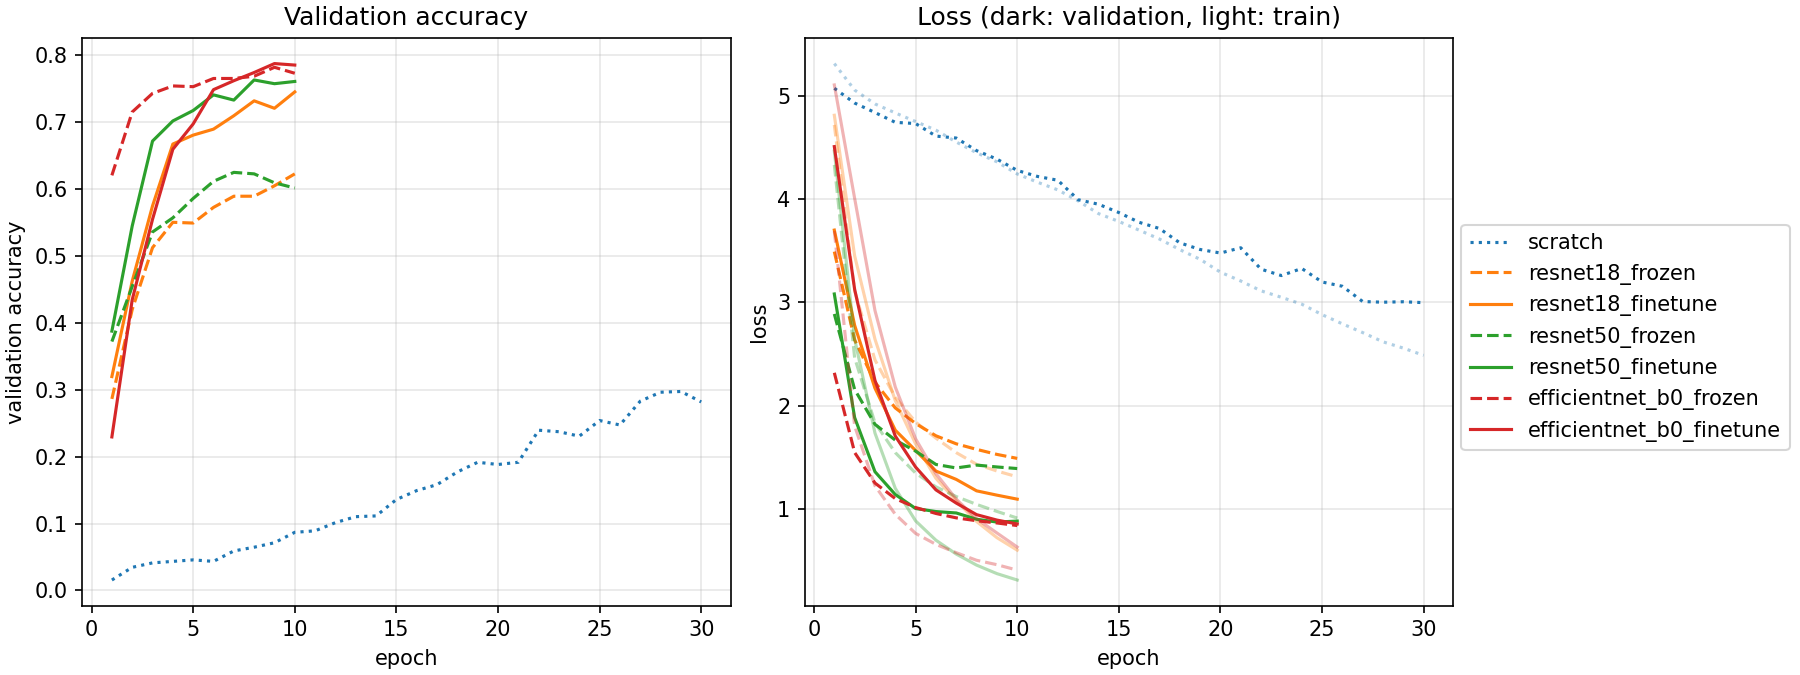

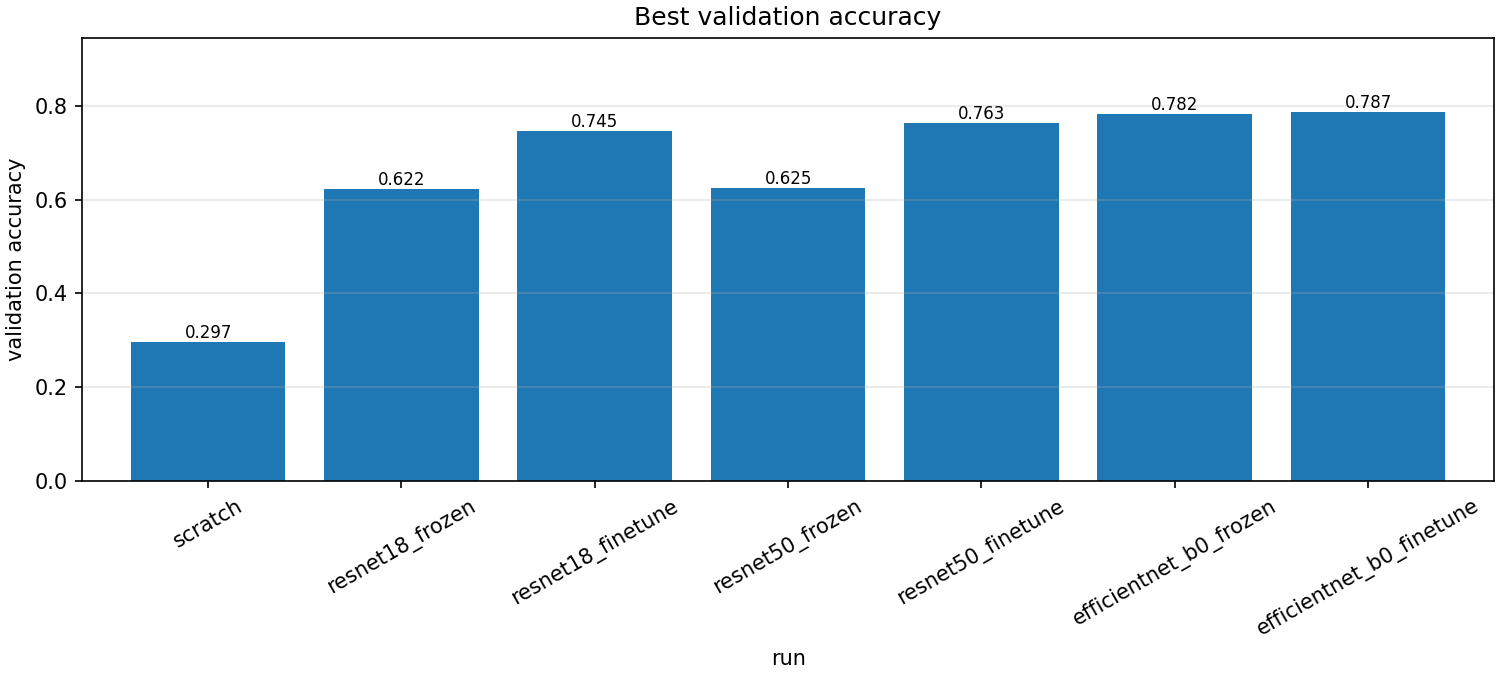

In [20]:
# 7. Save the project's comparison table and learning-curve figures.
from IPython.display import Image, display
from src.transfer import report

FIG_DIR.mkdir(parents=True, exist_ok=True)
comparison = report(CONFIG, TABLE_DIR, FIG_DIR, RUNS_DIR)
display(comparison.sort_values("best_val_accuracy", ascending=False))
display(Image(filename=str(FIG_DIR / "transfer_learning_curves.png")))
display(Image(filename=str(FIG_DIR / "transfer_validation_scores.png")))

In [21]:
# 8. Evaluate all seven saved best-epoch checkpoints on VALIDATION.
# This uses the project's accuracy, top-5, macro precision/recall/F1, confusion and per-class reports.
from src.evaluation.report import run_evaluation

EVAL_TABLE_DIR = TABLE_DIR / "evaluation"
EVAL_FIG_DIR = FIG_DIR / "evaluation"
selected_runs = [run["name"] for run in run_configs(CONFIG, RUN_NAMES)]
validation_table = run_evaluation(
    DATA_DIR, RUNS_DIR, checkpoint_dir, EVAL_TABLE_DIR, EVAL_FIG_DIR,
    selected_runs=selected_runs, test_run=None, num_workers=NUM_WORKERS, device="auto"
)
display(validation_table[["encoder", "mode", "accuracy", "top5_accuracy",
                          "precision_macro", "recall_macro", "f1_macro", "train_minutes"]])
print("Validation report:", EVAL_TABLE_DIR / "validation_comparison.csv")

saved /content/drive/MyDrive/bird_caption_generator/outputs/figures/evaluation/validation_scratch_top_confusions.png
validated scratch: accuracy 0.297, macro F1 0.278
saved /content/drive/MyDrive/bird_caption_generator/outputs/figures/evaluation/validation_resnet18_frozen_top_confusions.png
validated resnet18_frozen: accuracy 0.622, macro F1 0.605
saved /content/drive/MyDrive/bird_caption_generator/outputs/figures/evaluation/validation_resnet18_finetune_top_confusions.png
validated resnet18_finetune: accuracy 0.745, macro F1 0.728
saved /content/drive/MyDrive/bird_caption_generator/outputs/figures/evaluation/validation_resnet50_frozen_top_confusions.png
validated resnet50_frozen: accuracy 0.625, macro F1 0.607
saved /content/drive/MyDrive/bird_caption_generator/outputs/figures/evaluation/validation_resnet50_finetune_top_confusions.png
validated resnet50_finetune: accuracy 0.763, macro F1 0.753
saved /content/drive/MyDrive/bird_caption_generator/outputs/figures/evaluation/validation_eff

,encoder,mode,accuracy,top5_accuracy,precision_macro,recall_macro,f1_macro,train_minutes
run,,,,,,,,
efficientnet_b0_finetune,efficientnet_b0,fine-tune,0.787305,0.954343,0.803748,0.78550,0.776796,10.170165
efficientnet_b0_frozen,efficientnet_b0,frozen,0.781737,0.955457,0.807565,0.78075,0.771588,9.760716
resnet50_finetune,resnet50,fine-tune,0.762806,0.936526,0.803972,0.76225,0.752892,12.785930
resnet18_finetune,resnet18,fine-tune,0.744989,0.909800,0.760998,0.74400,0.727915,9.293815
resnet50_frozen,resnet50,frozen,0.624722,0.878619,0.682396,0.62225,0.607337,10.393797
resnet18_frozen,resnet18,frozen,0.622494,0.870824,0.673094,0.62225,0.605123,8.192261
scratch,scratch,from scratch,0.297327,0.587973,0.309819,0.29575,0.277961,25.376707


Validation report: /content/drive/MyDrive/bird_caption_generator/outputs/tables/evaluation/validation_comparison.csv


## Final test: one model only

Choose the final model from the validation comparison above. Set its name below and run the cell once. Leave `FINAL_TEST_RUN = None` while comparing candidates. The test report is stored in a separate `final_test` folder so it does not replace the all-model validation comparison.

In [22]:
# 9. Optional final test after selecting ONE model on validation.
FINAL_TEST_RUN = None  # Example: "efficientnet_b0_finetune"
if FINAL_TEST_RUN is not None:
    assert FINAL_TEST_RUN in selected_runs, "Choose a name from selected_runs"
    final_table = run_evaluation(
        DATA_DIR, RUNS_DIR, checkpoint_dir,
        EVAL_TABLE_DIR / "final_test", EVAL_FIG_DIR / "final_test",
        selected_runs=[FINAL_TEST_RUN], test_run=FINAL_TEST_RUN,
        num_workers=NUM_WORKERS, device="auto"
    )
    print("Final test report:", EVAL_TABLE_DIR / "final_test/final_test_metrics.csv")
else:
    print("Test split untouched. Choose one model after reviewing validation results.")

Test split untouched. Choose one model after reviewing validation results.


## Saved evidence

Drive keeps the checkpoint files in `bird_caption_generator/models`, the per-run training JSON and comparison CSV in `bird_caption_generator/outputs/tables/transfer_runs` and `tables`, the validation metrics and confusion tables in `tables/evaluation`, the figures in `figures`, and TensorBoard logs in `tensorboard`. Copy reviewed results and images into the project for documentation when you are ready. Do not commit large checkpoint files unless your team has decided how to store them.